--- REPEAT GROUND TRACK ANALYSIS: 15 orbits in 1 nodal day(s) ---
J2-Compensated Altitude: 561.63 km
Westward Longitudinal Drift per Orbit: 23.95 deg


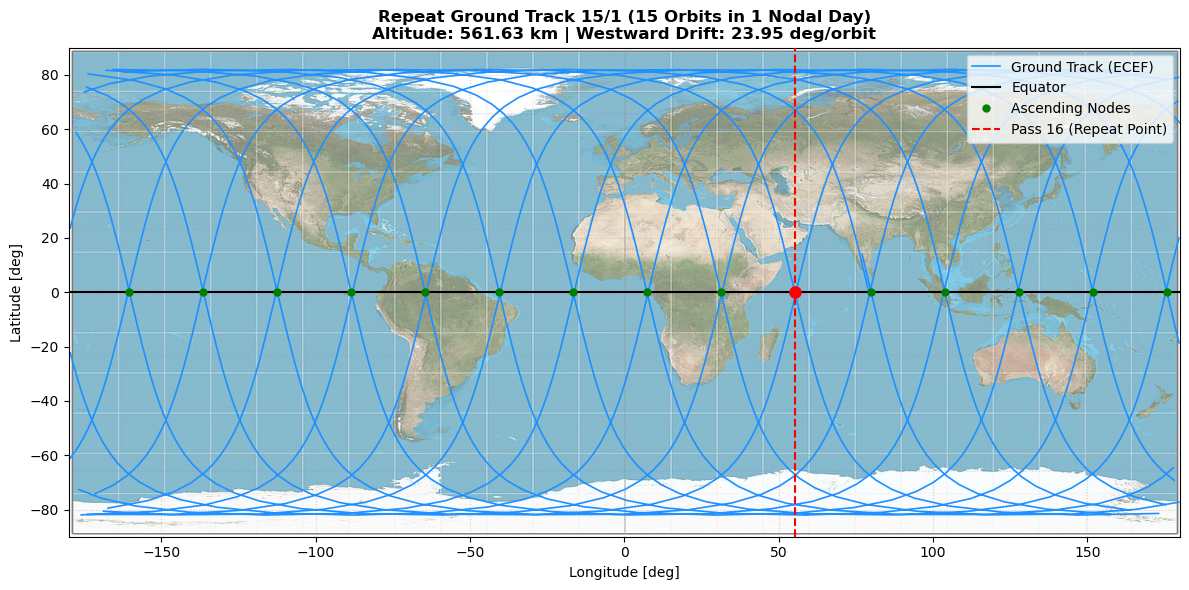

In [2]:
import math
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import orekit
from orekit.pyhelpers import setup_orekit_curdir

# =========================================================================
# 1. OREKIT ENVIRONMENT INITIALIZATION
# =========================================================================
orekit.initVM()
setup_orekit_curdir('C:/Users/Simone/Downloads/orekit-data-main')

from org.orekit.orbits import KeplerianOrbit, PositionAngleType
from org.orekit.frames import FramesFactory
from org.orekit.time import TimeScalesFactory, AbsoluteDate
from org.orekit.utils import Constants, IERSConventions
from org.orekit.propagation.analytical import EcksteinHechlerPropagator
from org.orekit.models.earth import ReferenceEllipsoid

# =========================================================================
# 2. REPEAT-GROUND-TRACK RATIO DEFINITION & J2-COMPENSATED SIZING
# =========================================================================
R = 15   # Number of orbital revolutions
D = 1    # Number of nodal days

print(f"--- REPEAT GROUND TRACK ANALYSIS: {R} orbits in {D} nodal day(s) ---")

mu = Constants.WGS84_EARTH_MU
R_earth = Constants.WGS84_EARTH_EQUATORIAL_RADIUS
J2 = -Constants.WGS84_EARTH_C20
omega_earth = Constants.WGS84_EARTH_ANGULAR_VELOCITY

inc = math.radians(98.0)
ecc = 0.001

# Initial unperturbed semi-major axis guess
T_init = (D * (2.0 * math.pi / omega_earth)) / R
a = math.pow(mu * (T_init / (2.0 * math.pi))**2, 1.0 / 3.0)

# Iterative semi-major axis refinement accounting for J2 secular perturbations
for _ in range(10):
    p = a * (1.0 - ecc**2)
    n = math.sqrt(mu / a**3)

    d_RAAN = -1.5 * J2 * (R_earth / p)**2 * n * math.cos(inc)
    d_argp =  0.75 * J2 * (R_earth / p)**2 * n * (5.0 * math.cos(inc)**2 - 1.0)
    d_M    =  0.75 * J2 * (R_earth / p)**2 * n * math.sqrt(1.0 - ecc**2) * (3.0 * math.cos(inc)**2 - 1.0)

    # Relative Earth rotation rate with respect to the precessing orbital plane
    omega_rel = omega_earth - d_RAAN
    T_nodal = (D * 2.0 * math.pi) / (R * omega_rel)

    # Solve for the Keplerian mean motion required to match the target nodal period
    n_target = (2.0 * math.pi) / T_nodal
    n_kep = n_target - (d_M + d_argp)
    a = math.pow(mu / (n_kep**2), 1.0 / 3.0)

alt_km = (a - R_earth) / 1000.0
print(f"J2-Compensated Altitude: {alt_km:.2f} km")

# =========================================================================
# 3. ORBIT PROPAGATION AND GROUND TRACK GENERATION
# =========================================================================
utc = TimeScalesFactory.getUTC()
epoch = AbsoluteDate(2026, 1, 1, 12, 0, 0.0, utc)
inertial_frame = FramesFactory.getEME2000()
earth_frame = FramesFactory.getITRF(IERSConventions.IERS_2010, True)

# Initialize orbit and analytical J2 propagator (osculating initial state)
orbit = KeplerianOrbit(a, ecc, inc, 0.0, 0.0, 0.0, PositionAngleType.MEAN, inertial_frame, epoch, mu)
propagator = EcksteinHechlerPropagator(
    orbit, Constants.WGS84_EARTH_EQUATORIAL_RADIUS,
    mu, Constants.WGS84_EARTH_C20, 0.0, 0.0, 0.0, 0.0
)

# Propagate over exactly D nodal days to verify ground-track closure
duration = D * (2.0 * math.pi / omega_rel)
times = np.arange(0.0, duration + 60.0, 60.0)

lats, lons = [], []
earth = ReferenceEllipsoid.getWgs84(earth_frame)

for t in times:
    state = propagator.propagate(epoch.shiftedBy(float(t)))
    point = earth.transform(state.getPVCoordinates().getPosition(), inertial_frame, state.getDate())
    lats.append(math.degrees(point.getLatitude()))
    lons.append(math.degrees(point.getLongitude()))

lons_arr = np.array(lons)
lats_arr = np.array(lats)

# =========================================================================
# 4. ASCENDING NODE DETECTION AND LONGITUDINAL DRIFT CALCULATION
# =========================================================================
crossings = np.where((lats_arr[:-1] < 0) & (lats_arr[1:] >= 0))[0]
cross_lons = []

for idx in crossings:
    lat1, lat2 = lats_arr[idx], lats_arr[idx + 1]
    lon1, lon2 = lons_arr[idx], lons_arr[idx + 1]
    if abs(lon2 - lon1) < 180.0:
        lon_cross = lon1 + (0.0 - lat1) * (lon2 - lon1) / (lat2 - lat1)
        cross_lons.append(lon_cross)

drift = 0.0
if len(cross_lons) > 1:
    drift = (cross_lons[0] - cross_lons[1]) % 360.0
    if drift > 180.0:
        drift = 360.0 - drift
print(f"Westward Longitudinal Drift per Orbit: {drift:.2f} deg")

# =========================================================================
# 5. GRAPHICAL VISUALIZATION
# =========================================================================
# Insert NaNs to prevent horizontal wrap-around artifacts at the +/-180 deg meridian
diffs = np.abs(np.diff(lons_arr))
split_idx = np.where(diffs > 180.0)[0] + 1
lons_plot = np.insert(lons_arr, split_idx, np.nan)
lats_plot = np.insert(lats_arr, split_idx, np.nan)

fig, ax = plt.subplots(figsize=(12, 6))

# Load background Earth map
try:
    img = mpimg.imread('C:/Users/Simone/Downloads/mappa_terra.jpg')
    ax.imshow(img, extent=[-180, 180, -90, 90], aspect='auto', alpha=0.6, zorder=0)
except FileNotFoundError:
    print("Background map image not found. Proceeding with blank axes.")

# Ground track
ax.plot(lons_plot, lats_plot, color='dodgerblue', linewidth=1.2, label='Ground Track (ECEF)', zorder=2)

# Equator reference line
ax.axhline(0, color='black', linewidth=1.5, label='Equator', zorder=3)

# Ascending node crossings
ax.plot(cross_lons, np.zeros_like(cross_lons), 'go', markersize=5, label='Ascending Nodes', zorder=5)

# Reference node to highlight ground-track closure
if len(cross_lons) > 0:
    first_node = cross_lons[0]
    ax.plot(first_node, 0, 'ro', markersize=8, zorder=6)
    ax.axvline(first_node, color='red', linestyle='--', linewidth=1.5, label=f'Pass {R+1} (Repeat Point)', zorder=4)

ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_xlabel("Longitude [deg]")
ax.set_ylabel("Latitude [deg]")
ax.set_title(
    f"Repeat Ground Track {R}/{D} ({R} Orbits in {D} Nodal Day)\n"
    f"Altitude: {alt_km:.2f} km | Westward Drift: {drift:.2f} deg/orbit",
    fontweight='bold'
)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right')

plt.tight_layout()
plt.show()